In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
from google.colab import files
uploaded=files.upload()

Saving train.csv to train (1).csv


In [30]:
df = pd.read_csv('/content/train.csv')

# Display success message
print("Dataset loaded successfully")
df

Dataset loaded successfully


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [31]:
# Display the first five rows of the dataset
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [32]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns)

Dataset shape: (614, 13)

Column names:
Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')


In [33]:
# Display column names, data types, and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [34]:
# Count missing values in each column
print(df.isnull().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [35]:
# Count approved and rejected loan applications
print(df['Loan_Status'].value_counts())

Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [36]:
# Count duplicate rows in the dataset
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


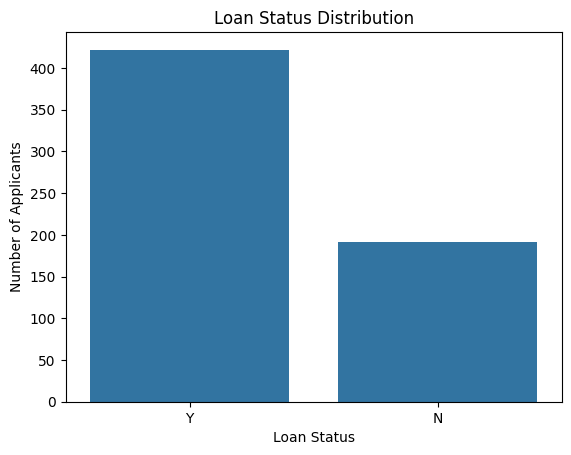

In [37]:
# Plot the number of approved and rejected loans
sns.countplot(data=df, x='Loan_Status')

# Add graph headings and labels
plt.title('Loan Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Applicants')
plt.show()

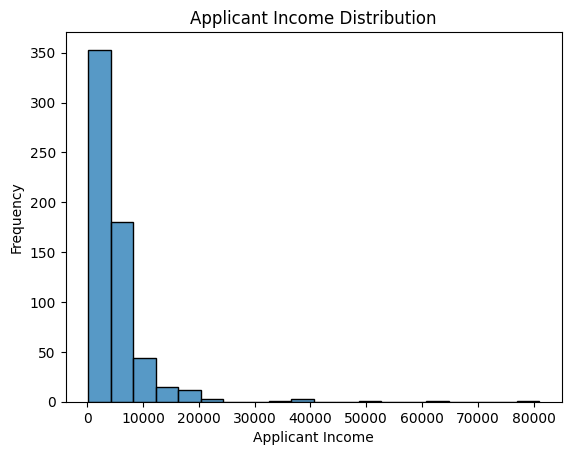

In [38]:
# Plot the distribution of applicant income
sns.histplot(data=df, x='ApplicantIncome', bins=20)

# Add graph headings and labels
plt.title('Applicant Income Distribution')
plt.xlabel('Applicant Income')
plt.ylabel('Frequency')
plt.show()

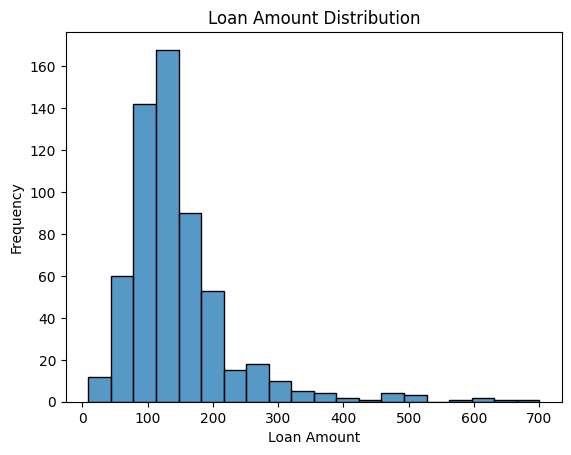

In [39]:
# Plot the distribution of loan amounts
sns.histplot(data=df, x='LoanAmount', bins=20)

# Add graph headings and labels
plt.title('Loan Amount Distribution')
plt.xlabel('Loan Amount')
plt.ylabel('Frequency')
plt.show()

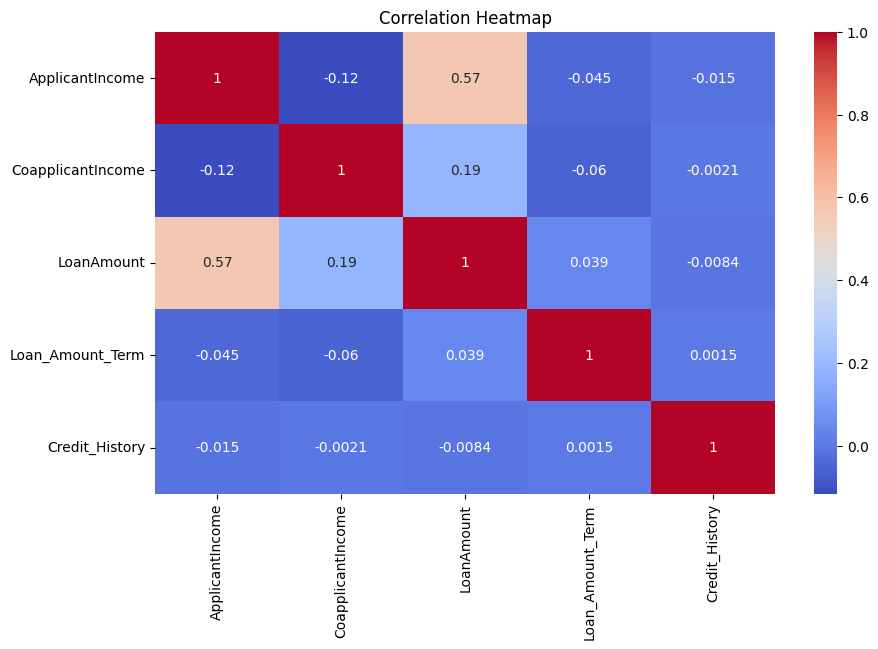

In [40]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate and display correlations
plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

# Add graph heading
plt.title('Correlation Heatmap')
plt.show()

In [41]:
# Remove the applicant ID column
df = df.drop('Loan_ID', axis=1)

# Display the updated columns
print(df.columns)

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')


In [42]:
# Fill missing values in each column
for col in df.columns:

    # Fill categorical columns with the most frequent value
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])

    # Fill numerical columns with the median
    else:
        df[col] = df[col].fillna(df[col].median())

# Check missing values after preprocessing
print(df.isnull().sum())

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [43]:
# Convert categorical columns into numerical columns
df = pd.get_dummies(df, drop_first=True, dtype=int)

# Display the encoded dataset
df.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Loan_Status_Y
0,5849,0.0,128.0,360.0,1.0,1,0,0,0,0,0,0,0,1,1
1,4583,1508.0,128.0,360.0,1.0,1,1,1,0,0,0,0,0,0,0
2,3000,0.0,66.0,360.0,1.0,1,1,0,0,0,0,1,0,1,1
3,2583,2358.0,120.0,360.0,1.0,1,1,0,0,0,1,0,0,1,1
4,6000,0.0,141.0,360.0,1.0,1,0,0,0,0,0,0,0,1,1


In [44]:
# Select input features
X = df.drop('Loan_Status_Y', axis=1)

# Select the target column
y = df['Loan_Status_Y']

# Display the shapes of features and target
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (614, 14)
Target shape: (614,)


In [45]:
# Import the function for splitting the dataset
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display the size of training and testing data
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (491, 14)
Testing data: (123, 14)


In [46]:
# Import the Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Train the model using training data
model.fit(X_train, y_train)

# Display success message
print("Random Forest model trained successfully")

Random Forest model trained successfully


In [47]:
# Display the five most important features
print(importance.head(5))

Credit_History       0.435388
ApplicantIncome      0.124972
LoanAmount           0.112001
CoapplicantIncome    0.097335
Loan_Amount_Term     0.057222
dtype: float64


In [48]:
# Predict the target values for testing data
y_pred = model.predict(X_test)

# Import the accuracy metric
from sklearn.metrics import accuracy_score

# Calculate and display accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8536585365853658


In [49]:
# Import the classification report
from sklearn.metrics import classification_report

# Display precision, recall, F1-score, and support
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.55      0.70        38
           1       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



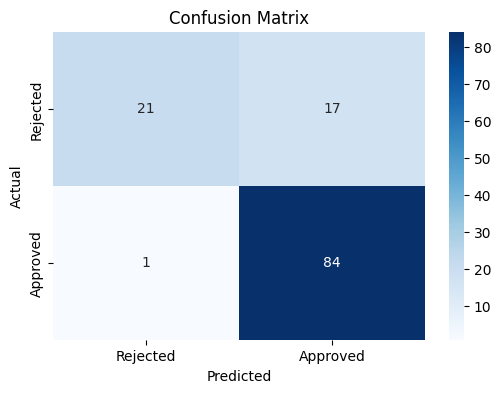

In [50]:
# Import the confusion matrix function
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix as a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Rejected', 'Approved'],
    yticklabels=['Rejected', 'Approved']
)

# Add graph headings and labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

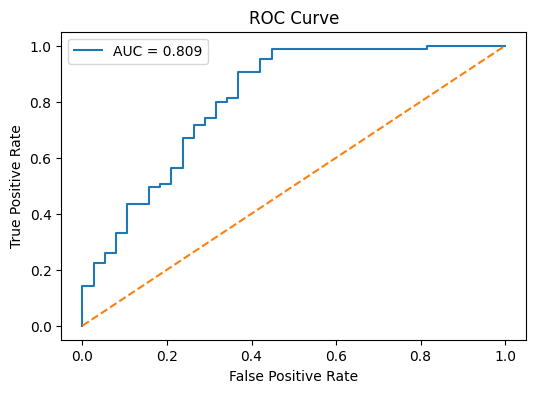

ROC-AUC Score: 0.8086687306501549


In [51]:
# Import ROC curve and AUC functions
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate predicted probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate false positive rate and true positive rate
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC score
auc_score = roc_auc_score(y_test, y_prob)

# Plot the ROC curve
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'AUC = {auc_score:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')

# Add graph headings and labels
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Display AUC score
print("ROC-AUC Score:", auc_score)

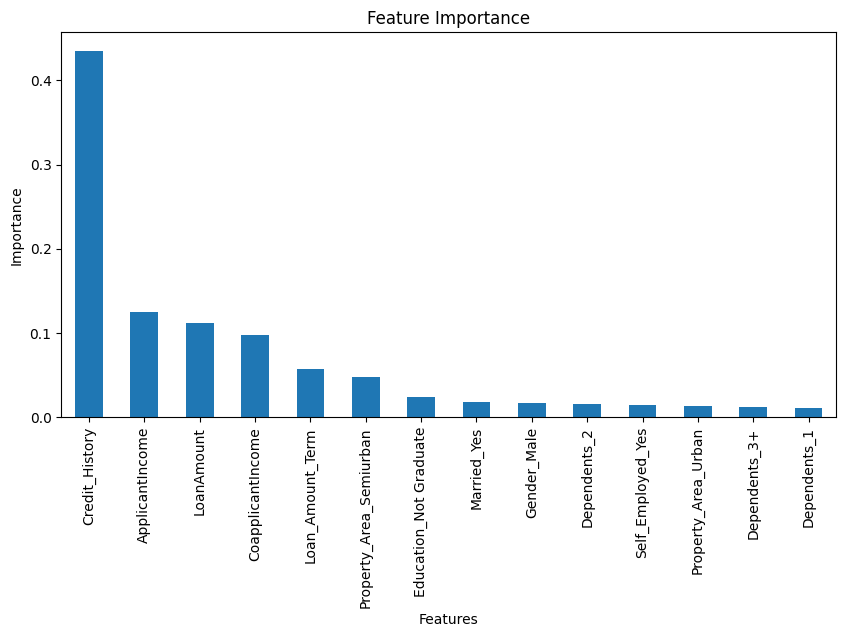

In [52]:
# Calculate the importance of each feature
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

# Plot feature importance
importance.plot(kind='bar', figsize=(10, 5))

# Add graph headings and labels
plt.title('Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()

## Conclusion

The Random Forest Classification algorithm was used to predict loan approval status using applicant information. The dataset contained 614 records and 13 columns. Missing values were handled, and categorical data was converted into numerical form.

The model achieved an accuracy of **85.37%** and an ROC-AUC score of approximately **0.809**. It performed well at identifying approved loan applications, but it had difficulty identifying some rejected applications.

The confusion matrix, ROC curve, and feature importance graph helped evaluate the model's performance. In the future, the model could be improved using hyperparameter tuning, cross-validation, and comparison with other classification algorithms.